# Retail Sales Analytics for Inventory Planning
## 1. Getting to Know the Data
Before analyzing sales, I want to understand the dataset, how sales are recorded, and whether there are any data quality issues.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

## 2. Loading the Dataset

In [36]:
calendar_path = "/Users/kat/Documents/retail-demand-forecasting/data/raw/calendar.csv"

calendar = pd.read_csv(calendar_path)

calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [37]:
calendar["date"] = pd.to_datetime(calendar["date"])

print(f"Calendar period: {calendar['date'].min().date()} — {calendar['date'].max().date()}")
print(f"Number of days: {calendar.shape[0]}")
print(f"Number of columns: {calendar.shape[1]}")

calendar.info()

Calendar period: 2011-01-29 — 2016-06-19
Number of days: 1969
Number of columns: 14
<class 'pandas.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1969 non-null   datetime64[us]
 1   wm_yr_wk      1969 non-null   int64         
 2   weekday       1969 non-null   str           
 3   wday          1969 non-null   int64         
 4   month         1969 non-null   int64         
 5   year          1969 non-null   int64         
 6   d             1969 non-null   str           
 7   event_name_1  162 non-null    str           
 8   event_type_1  162 non-null    str           
 9   event_name_2  5 non-null      str           
 10  event_type_2  5 non-null      str           
 11  snap_CA       1969 non-null   int64         
 12  snap_TX       1969 non-null   int64         
 13  snap_WI       1969 non-null   int64         
dtypes: datetime64[u

### Do holidays and special events affect demand?
The calendar includes holidays, cultural events and SNAP-related indicators. I will compare sales on event and non-event days to see whether they are useful planning signals.

In [38]:
events = calendar[
    calendar["event_name_1"].notna() |
    calendar["event_name_2"].notna()
][
    ["date", "event_name_1", "event_type_1", "event_name_2", "event_type_2"]
]

events.head(10)

,date,event_name_1,event_type_1,event_name_2,event_type_2
8,2011-02-06,SuperBowl,Sporting,NaN,NaN
16,2011-02-14,ValentinesDay,Cultural,NaN,NaN
23,2011-02-21,PresidentsDay,National,NaN,NaN
39,2011-03-09,LentStart,Religious,NaN,NaN
46,2011-03-16,LentWeek2,Religious,NaN,NaN
47,2011-03-17,StPatricksDay,Cultural,NaN,NaN
50,2011-03-20,Purim End,Religious,NaN,NaN
85,2011-04-24,OrthodoxEaster,Religious,Easter,Cultural
87,2011-04-26,Pesach End,Religious,NaN,NaN
96,2011-05-05,Cinco De Mayo,Cultural,NaN,NaN


### What does the sales data look like?

Each row represents one product sold in one store. Daily sales are stored in separate columns, so we will later reshape the table for analysis.

In [39]:
sales_path = "/Users/kat/Documents/retail-demand-forecasting/data/raw/sales_train_validation.csv"

sales_sample = pd.read_csv(sales_path, nrows=5)

sales_sample.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,d_11,d_12,d_13,d_14,d_15,d_16,d_17,d_18,d_19,...,d_1889,d_1890,d_1891,d_1892,d_1893,d_1894,d_1895,d_1896,d_1897,d_1898,d_1899,d_1900,d_1901,d_1902,d_1903,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,4,2,3,0,1,2,0,0,0,1,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0,0,0,0,1,2,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,3,1,2,1,3,1,0,2,5,4,2,0,3,0,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,4,0,1,4,0,1,0,1,0,1,1,2,0,1,1,2,1,1,0,1,1,2,2,2,4


In [40]:
sales_sample.columns.tolist()

['id',
 'item_id',
 'dept_id',
 'cat_id',
 'store_id',
 'state_id',
 'd_1',
 'd_2',
 'd_3',
 'd_4',
 'd_5',
 'd_6',
 'd_7',
 'd_8',
 'd_9',
 'd_10',
 'd_11',
 'd_12',
 'd_13',
 'd_14',
 'd_15',
 'd_16',
 'd_17',
 'd_18',
 'd_19',
 'd_20',
 'd_21',
 'd_22',
 'd_23',
 'd_24',
 'd_25',
 'd_26',
 'd_27',
 'd_28',
 'd_29',
 'd_30',
 'd_31',
 'd_32',
 'd_33',
 'd_34',
 'd_35',
 'd_36',
 'd_37',
 'd_38',
 'd_39',
 'd_40',
 'd_41',
 'd_42',
 'd_43',
 'd_44',
 'd_45',
 'd_46',
 'd_47',
 'd_48',
 'd_49',
 'd_50',
 'd_51',
 'd_52',
 'd_53',
 'd_54',
 'd_55',
 'd_56',
 'd_57',
 'd_58',
 'd_59',
 'd_60',
 'd_61',
 'd_62',
 'd_63',
 'd_64',
 'd_65',
 'd_66',
 'd_67',
 'd_68',
 'd_69',
 'd_70',
 'd_71',
 'd_72',
 'd_73',
 'd_74',
 'd_75',
 'd_76',
 'd_77',
 'd_78',
 'd_79',
 'd_80',
 'd_81',
 'd_82',
 'd_83',
 'd_84',
 'd_85',
 'd_86',
 'd_87',
 'd_88',
 'd_89',
 'd_90',
 'd_91',
 'd_92',
 'd_93',
 'd_94',
 'd_95',
 'd_96',
 'd_97',
 'd_98',
 'd_99',
 'd_100',
 'd_101',
 'd_102',
 'd_103',
 'd_104',


In [41]:
sales_info = pd.read_csv(sales_path, nrows=0)

print(f"Number of columns: {len(sales_info.columns)}")
print(f"Number of daily sales columns: {len(sales_info.columns) - 6}")

Number of columns: 1919
Number of daily sales columns: 1913


In [42]:
sales = pd.read_csv(sales_path)

print(f"Rows: {sales.shape[0]:,}")
print(f"Columns: {sales.shape[1]:,}")

Rows: 30,490
Columns: 1,919


In [43]:
print("Products:", sales["item_id"].nunique())
print("Stores:", sales["store_id"].nunique())
print("Categories:", sales["cat_id"].nunique())

sales[["item_id", "dept_id", "cat_id", "store_id", "state_id"]].head()

Products: 3049
Stores: 10
Categories: 3


,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA


### What we learned

The dataset contains 30,490 product-store records covering 3,049 products across 10 stores.

Each record includes 1,913 daily sales values. These values are stored in separate columns, so the dataset is currently in a wide format. For the next part of the analysis, I will reshape it into a long format with one row per product, store and date.

## 4. Comparing Product Categories

Before looking at individual products, I want to compare total sales across the three main categories in the dataset.

In [44]:
day_columns = [col for col in sales.columns if col.startswith("d_")]

category_sales = (
    sales.groupby("cat_id")[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
    .rename("total_units_sold")
    .reset_index()
)

category_sales

,cat_id,total_units_sold
0,FOODS,45089939
1,HOUSEHOLD,14480670
2,HOBBIES,6124800


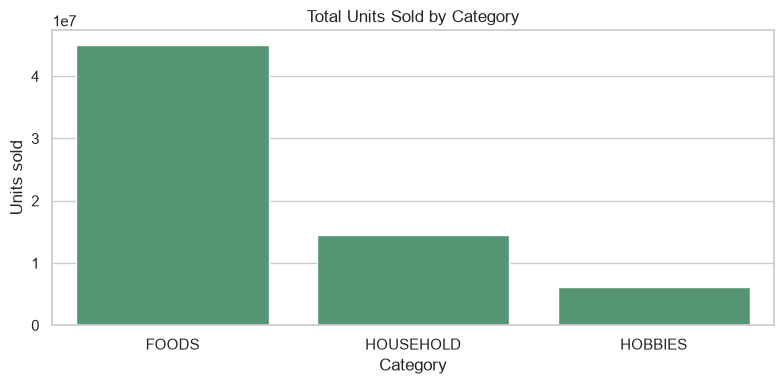

In [45]:
plt.figure(figsize=(8, 4))
sns.barplot(data=category_sales, x="cat_id", y="total_units_sold", color="#4C9F70")
plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units sold")
plt.tight_layout()
plt.show()

### What stands out?

FOODS has the highest total sales by a wide margin, followed by HOUSEHOLD and HOBBIES. This difference is important for inventory planning because the categories may require different replenishment priorities and stock policies.

In [46]:
store_sales = (
    sales.groupby(["state_id", "store_id"])[day_columns]
    .sum()
    .sum(axis=1)
    .sort_values(ascending=False)
    .rename("total_units_sold")
    .reset_index()
)

store_sales

,state_id,store_id,total_units_sold
0,CA,CA_3,11188180
1,CA,CA_1,7698216
2,TX,TX_2,7214384
3,WI,WI_2,6544012
4,WI,WI_3,6427782
5,TX,TX_3,6089330
6,CA,CA_2,5685475
7,TX,TX_1,5595292
8,WI,WI_1,5149062
9,CA,CA_4,4103676


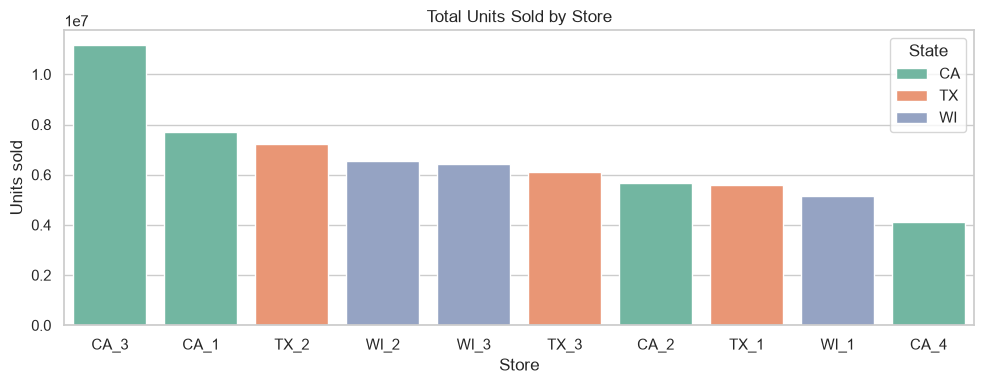

In [47]:
plt.figure(figsize=(10, 4))
sns.barplot(data=store_sales, x="store_id", y="total_units_sold", hue="state_id", dodge=False, palette="Set2")
plt.title("Total Units Sold by Store")
plt.xlabel("Store")
plt.ylabel("Units sold")
plt.legend(title="State")
plt.tight_layout()
plt.show()

## 5. Comparing Stores

CA_3 has the highest total sales with 11.2 million units. CA_4 has the lowest with 4.1 million units. This difference shows that demand depends on location, so stores should not all use the same inventory policy.

In [48]:

daily_sales = sales[day_columns].sum(axis=0).reset_index()
daily_sales.columns = ['d', 'units_sold']
daily_sales = daily_sales.merge(calendar[['d', 'date', 'weekday', 'month', 'year']], on='d', how='left')
daily_sales.head()

,d,units_sold,date,weekday,month,year
0,d_1,32631,2011-01-29,Saturday,1,2011
1,d_2,31749,2011-01-30,Sunday,1,2011
2,d_3,23783,2011-01-31,Monday,1,2011
3,d_4,25412,2011-02-01,Tuesday,2,2011
4,d_5,19146,2011-02-02,Wednesday,2,2011


## 6. Daily Sales Dynamics

I aggregated sales across all products and stores to see how total demand changes over time. This helps identify recurring patterns and unusual peaks that may affect replenishment planning.

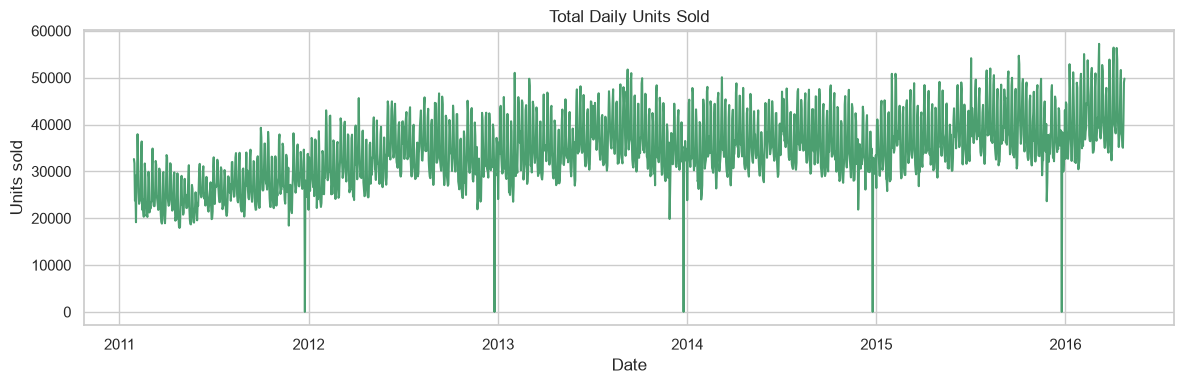

In [49]:
plt.figure(figsize=(12, 4))
sns.lineplot(data=daily_sales, x='date', y='units_sold', color='#4C9F70')
plt.title('Total Daily Units Sold')
plt.xlabel('Date')
plt.ylabel('Units sold')
plt.tight_layout()
plt.show()

### What stands out?

Daily sales fluctuate over time rather than staying constant. This suggests that replenishment planning should consider timing and recurring demand patterns, not only total sales volume.

In [51]:
weekday_sales = daily_sales.groupby('weekday', sort=False)['units_sold'].agg(['mean', 'median']).reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
weekday_sales

,mean,median
weekday,,
Monday,32852.967033,33444.0
Tuesday,30368.780220,30710.0
Wednesday,30010.021978,30911.0
Thursday,30205.007326,30658.0
Friday,34225.985348,34775.0
Saturday,41546.894161,42437.0
Sunday,41130.021898,42586.0


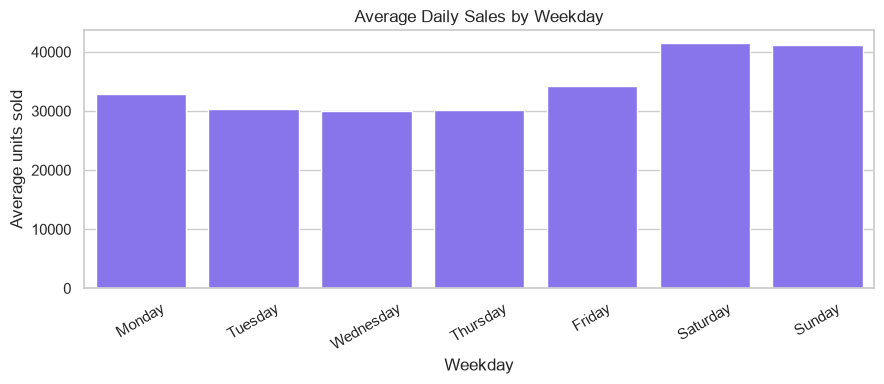

In [52]:

plt.figure(figsize=(9, 4))
sns.barplot(data=weekday_sales.reset_index(), x='weekday', y='mean', color='#7B61FF')
plt.title('Average Daily Sales by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average units sold')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### What stands out?

Sales are highest on Saturday and Sunday, while midweek demand is lower. This pattern can support higher weekend replenishment and staffing, especially for fast-moving products.

In [53]:

monthly_sales = daily_sales.groupby(['year', 'month'], as_index=False)['units_sold'].sum()
monthly_sales['month_name'] = pd.to_datetime(monthly_sales['month'], format='%m').dt.strftime('%b')
monthly_sales.head()

,year,month,units_sold,month_name
0,2011,1,88163,Jan
1,2011,2,726375,Feb
2,2011,3,763567,Mar
3,2011,4,737713,Apr
4,2011,5,719562,May


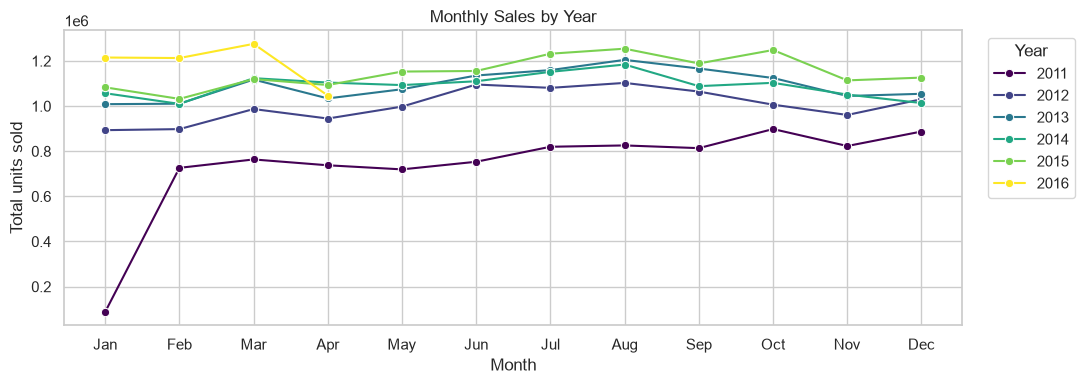

In [54]:

plt.figure(figsize=(11, 4))
sns.lineplot(data=monthly_sales, x='month_name', y='units_sold', hue='year', marker='o', palette='viridis')
plt.title('Monthly Sales by Year')
plt.xlabel('Month')
plt.ylabel('Total units sold')
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 7. Seasonal Patterns

Monthly sales change across the year and between years. This indicates that inventory planning should account for seasonal demand instead of using one average level for every month.

In [55]:

daily_sales_events = daily_sales.merge(calendar[['d', 'event_name_1', 'event_name_2']], on='d', how='left')
daily_sales_events['has_event'] = daily_sales_events['event_name_1'].notna() | daily_sales_events['event_name_2'].notna()
event_comparison = daily_sales_events.groupby('has_event')['units_sold'].agg(['mean', 'median', 'count'])
event_comparison.index = ['No recorded event', 'Event day']
event_comparison

,mean,median,count
No recorded event,34489.207504,33714.0,1759
Event day,32655.149351,33779.5,154


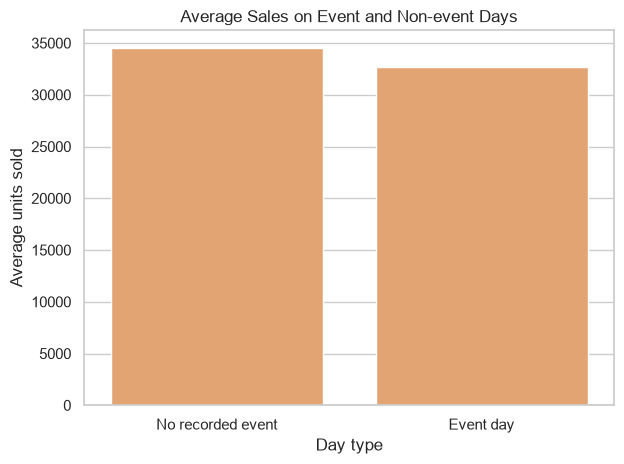

In [56]:

event_plot = event_comparison.reset_index().rename(columns={'index': 'day_type'})
sns.barplot(data=event_plot, x='day_type', y='mean', color='#F4A261')
plt.title('Average Sales on Event and Non-event Days')
plt.xlabel('Day type')
plt.ylabel('Average units sold')
plt.tight_layout()
plt.show()

## 8. Events and Holidays

The calendar contains 154 event days and 1,759 days without a recorded event. In this dataset, event days have a lower average total than non-event days, so an event should not automatically be treated as a demand increase. The effect may differ by product, category and store.

In [57]:

prices_path = "/Users/kat/Documents/retail-demand-forecasting/data/raw/sell_prices.csv"
prices = pd.read_csv(prices_path)
print(f"Rows: {prices.shape[0]:,}")
print(f"Columns: {prices.shape[1]:,}")
prices.head()

Rows: 6,841,121
Columns: 4


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


## 9. Price Data

The price table adds weekly selling prices by product, store and week. It can be used to review price ranges and to compare price changes with sales patterns. In this project, prices are treated as context for inventory analysis rather than as proof that price changes caused changes in demand.

In [58]:

product_sales = sales.groupby(['item_id', 'cat_id'])[day_columns].sum().sum(axis=1).rename('total_units_sold').reset_index()
product_sales = product_sales.sort_values('total_units_sold', ascending=False)
product_sales.head(10)

,item_id,cat_id,total_units_sold
702,FOODS_3_090,FOODS,1002529
1198,FOODS_3_586,FOODS,920242
864,FOODS_3_252,FOODS,565299
1167,FOODS_3_555,FOODS,491287
1325,FOODS_3_714,FOODS,396172
1199,FOODS_3_587,FOODS,396119
1306,FOODS_3_694,FOODS,390001
838,FOODS_3_226,FOODS,363082
814,FOODS_3_202,FOODS,295689
1334,FOODS_3_723,FOODS,284333


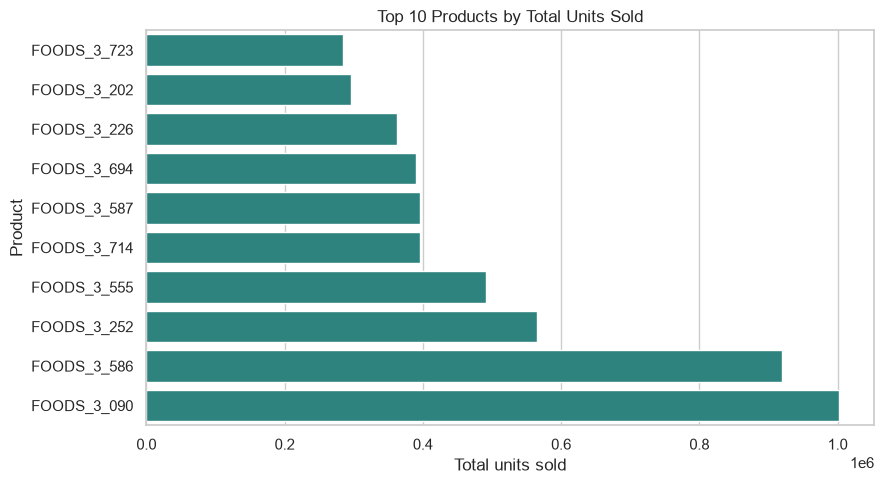

In [59]:

top_products = product_sales.head(10).sort_values('total_units_sold')
plt.figure(figsize=(9, 5))
sns.barplot(data=top_products, x='total_units_sold', y='item_id', hue='cat_id', dodge=False, legend=False, palette='viridis')
plt.title('Top 10 Products by Total Units Sold')
plt.xlabel('Total units sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

### What stands out?

The top-selling products are concentrated in the FOODS category. These products deserve closer monitoring because a stockout could affect a large share of total unit volume.

In [60]:

abc = product_sales.copy()
abc['share'] = abc['total_units_sold'] / abc['total_units_sold'].sum()
abc['cumulative_share'] = abc['share'].cumsum()
abc['abc_class'] = pd.cut(abc['cumulative_share'], bins=[0, 0.80, 0.95, 1.0], labels=['A', 'B', 'C'], include_lowest=True)
abc_summary = abc.groupby('abc_class', observed=False).agg(products=('item_id', 'count'), units=('total_units_sold', 'sum'), share=('share', 'sum'))
abc_summary['share'] = abc_summary['share'] * 100
abc_summary

,products,units,share
abc_class,,,
A,1033,52544890,79.982591
B,990,9860688,15.009706
C,1025,3289263,5.006838


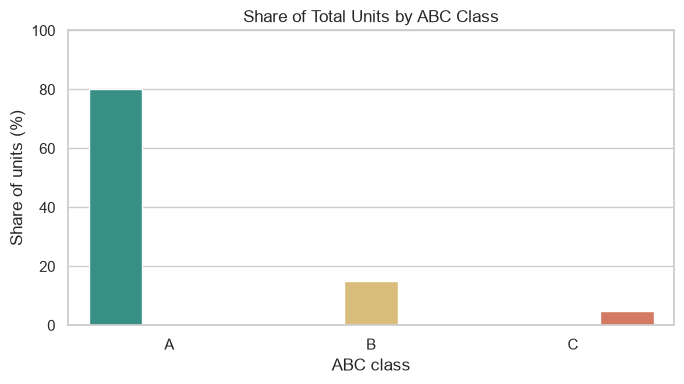

In [61]:

abc_plot = abc_summary.reset_index()
plt.figure(figsize=(7, 4))
sns.barplot(data=abc_plot, x='abc_class', y='share', hue='abc_class', palette=['#2A9D8F', '#E9C46A', '#E76F51'], legend=False)
plt.title('Share of Total Units by ABC Class')
plt.xlabel('ABC class')
plt.ylabel('Share of units (%)')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 10. ABC Analysis

Using the standard 80/15/5 rule as an analytical segmentation, A-items represent about 80% of unit volume, B-items about 15% and C-items about 5%. A-items should receive the most frequent monitoring and the strongest replenishment attention. The thresholds are a planning choice, not a prediction model.

## 11. Business Implications

- Prioritize FOODS and the highest-volume products when reviewing stock availability.
- Use store-specific inventory policies because sales volumes differ substantially by location.
- Prepare additional replenishment capacity for weekends and seasonal peaks.
- Use the event calendar as a planning signal, but check the effect by product and store before changing stock levels.
- Monitor A-class products most frequently because they account for most unit volume.
- Use price data as context when investigating changes in sales, without assuming that price alone explains demand.

## 12. Conclusion

This analysis reviewed retail sales across products, stores, categories and dates. The main findings are that FOODS generates the largest sales volume, demand varies by store, weekends are stronger than most weekdays, sales change across months, and a relatively focused group of products drives most unit volume. These findings can support practical inventory decisions such as store-specific replenishment, closer monitoring of A-items and extra preparation for recurring demand peaks.